# <font color='#FFE15D'>**Nonlinear Regression $ \sin(x) $ / $ \cos(x) $**</font>

## **🔸 Imports**

In [283]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## **🔸 Polynomial Regression (Univariate)**

### Functions

In [284]:
def polynomial(x):
    phi_x = np.array([x**i for i in range(d+1)])
    phi_x = phi_x[..., 0].T
    return phi_x

In [285]:
def linear_regression(x, w):
    y_hat = x @ w
    return y_hat

In [286]:
def mse(y, y_hat):
    loss = np.mean((y - y_hat)**2)
    return loss

In [287]:
def gradient(x, y, y_hat):
    grads = 2*(x.T @ (y_hat - y)) / y.shape[0]
    return grads

In [288]:
def gradient_descent(w, eta, grads):
    w -= eta*grads
    return w

In [289]:
def r2(y, y_hat):
    return 1 - np.sum((y - y_hat)**2) / np.sum((y - y.mean())**2)

### Train

#### - Initialization

In [290]:
d = 5

w = np.random.randn(d+1, 1)
print(w.shape)

eta = 0.6
n_epochs = 2000

(6, 1)


#### - Load Dataset

In [291]:
df = pd.read_csv('data/train-data.csv')
train_set = np.array(df)

x_train = train_set[:, :-1]
y_train = train_set[:, -1:]
x_train.shape, y_train.shape

((101, 1), (101, 1))

In [292]:
phi_x_train = polynomial(x_train)
phi_x_train.shape

(101, 6)

In [293]:
df

,x,y
0,0.00,0.00
1,0.01,0.03
2,0.02,0.06
3,0.03,0.09
4,0.04,0.13
...,...,...
96,0.96,0.13
97,0.97,0.09
98,0.98,0.06
99,0.99,0.03


#### - Main

In [294]:
error_list = []

for epoch in range(n_epochs):
    # predictions
    y_hat = linear_regression(phi_x_train, w)
    
    # loss
    e = mse(y_train, y_hat)
    error_list.append(e)
    
    # gradients
    grads = gradient(phi_x_train, y_train, y_hat)
    
    # gradient descent
    w = gradient_descent(w, eta, grads)
    
    if (epoch+1) % 100 == 0:
        print(f'Epoch={epoch}, \t E={e:.4},\t w={w.T[0]}')

Epoch=99, 	 E=0.008146,	 w=[ 0.23905121  1.80013367 -0.22988753 -1.10052821 -0.20205436 -0.63873776]
Epoch=199, 	 E=0.006169,	 w=[ 0.17330944  2.06235834 -0.31519418 -1.23208418 -0.26521195 -0.60581841]
Epoch=299, 	 E=0.005272,	 w=[ 0.15293636  2.19304409 -0.43097244 -1.33248804 -0.26522529 -0.49389361]
Epoch=399, 	 E=0.004517,	 w=[ 0.13910116  2.29941551 -0.54279258 -1.4227674  -0.25785154 -0.37986676]
Epoch=499, 	 E=0.003871,	 w=[ 0.12694696  2.39591711 -0.64674013 -1.50601893 -0.2501473  -0.27297043]
Epoch=599, 	 E=0.003318,	 w=[ 0.11578841  2.48491188 -0.74286355 -1.58306919 -0.24297237 -0.17383586]
Epoch=699, 	 E=0.002846,	 w=[ 0.10547897  2.56717127 -0.83167997 -1.6544215  -0.23639423 -0.08203105]
Epoch=799, 	 E=0.002441,	 w=[ 0.09594577  2.64322711 -0.91372845 -1.72050788 -0.23038182  0.00297417]
Epoch=899, 	 E=0.002095,	 w=[ 0.0871294   2.713548   -0.98951543 -1.78172363 -0.22489435  0.08168698]
Epoch=999, 	 E=0.001798,	 w=[ 0.07897597  2.7785644  -1.05951039 -1.83843389 -0.219

### Learning curve

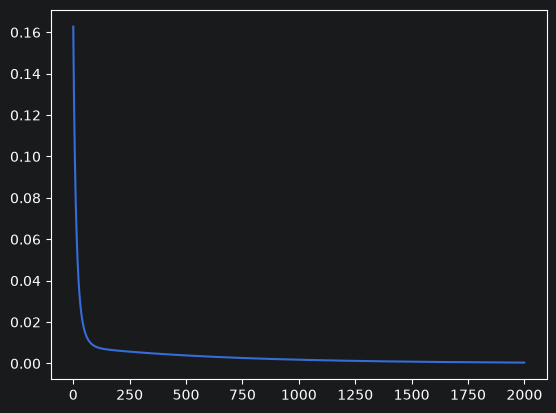

In [295]:

plt.plot(error_list)

### Save model

In [296]:
np.save('polynomial-linear-regression', w)

### Test

In [297]:
df = pd.read_csv('data/test-data.csv')
test_set = np.array(df)

x_test = test_set[:, :-1]
y_test = test_set[:, -1:]

x_test.shape, y_test.shape

((20, 1), (20, 1))

In [298]:
phi_x_test = polynomial(x_test)
phi_x_test.shape

(20, 6)

In [299]:
y_hat_test = linear_regression(phi_x_test, w)
y_hat_test.shape

(20, 1)

In [300]:
Result = r2(y_test,y_hat_test)
print(int(Result*100))
print(f'Metric = {Result*100:.2f}%')

99
Metric = 99.57%


### Visualize

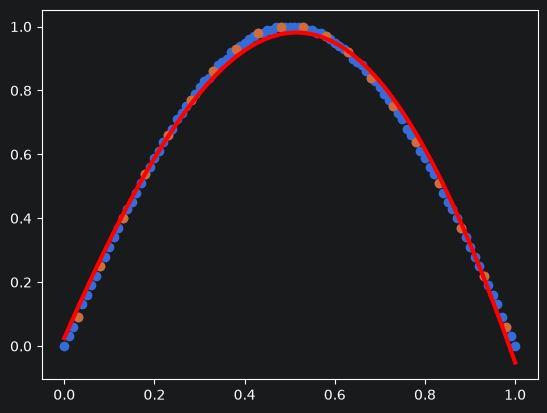

In [301]:
x = np.linspace(x_train.min(), x_train.max(), 100)[:, None]
xp = polynomial(x)
y_hat = linear_regression(xp, w)

plt.scatter(x_train, y_train)
plt.scatter(x_test, y_test)
plt.plot(x, y_hat, 'r', linewidth=3)